In [3]:
import csv
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as sp

Open the CSV file

In [4]:
with open('2018.csv', 'r') as file:
    csv_reader = csv.reader(file)
    # Read all rows into a list
    rows = list(csv_reader)

    # Convert the list of rows into a NumPy array
    data = np.array(rows)

Remove header row

In [5]:
data = data[1:, :]

check how much zeros are in each column

In [6]:
count = np.sum(data[:, 6] == "0.000")
print("There is", count, "value equal to zero in column 'Freedom'")
count = np.sum(data[:, 7] == "0.000")
print("There is", count, "value equal to zero in column 'Generosity'")

There is 1 value equal to zero in column 'Freedom'
There is 1 value equal to zero in column 'Generosity'


Erase row with a value of zero - there are only two<br>
We checked these countries on the internet and it doesnt make sense that its zero so we erase them

In [7]:
rows_to_remove = np.where(data[:, 6] == '0.000')[0]
# Remove the identified rows
data = np.delete(data, rows_to_remove, axis=0)
rows_to_remove = np.where(data[:, 7] == '0.000')[0]
# Remove the identified rows
data = np.delete(data, rows_to_remove, axis=0)

Remove the N/A values

In [8]:
NAvalues = np.where(data == 'N/A')
# Remove the identified rows
data[NAvalues] = '0.000'

Divide categories into different arrays

In [9]:
countries = data[:, 1]
rank = data[:, 0].astype(float)
freedom = data[:, 6].astype(float)
generosity = data[:, 7].astype(float)
GDP = data[:, 3].astype(float)
socialSupport = data[:, 4].astype(float)
lifex = data[:, 5].astype(float)
corruption = data[:, 8].astype(float)

There is no need here for normalisation because all the data is on the same scale

Graphs:

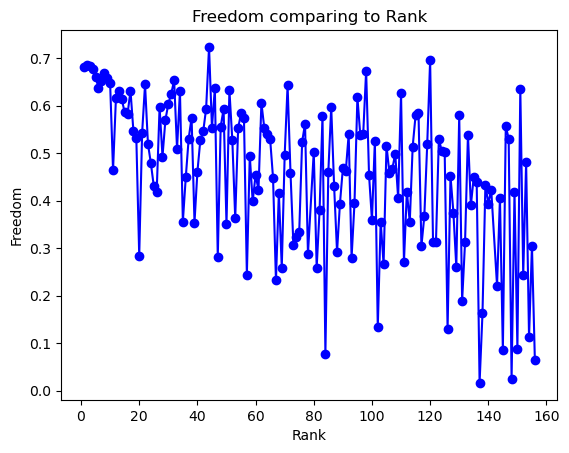

In [10]:
plt.plot(rank, freedom, marker='o', linestyle='-', color='blue')
plt.xlabel('Rank')
plt.ylabel('Freedom')
plt.title('Freedom comparing to Rank')
plt.show()

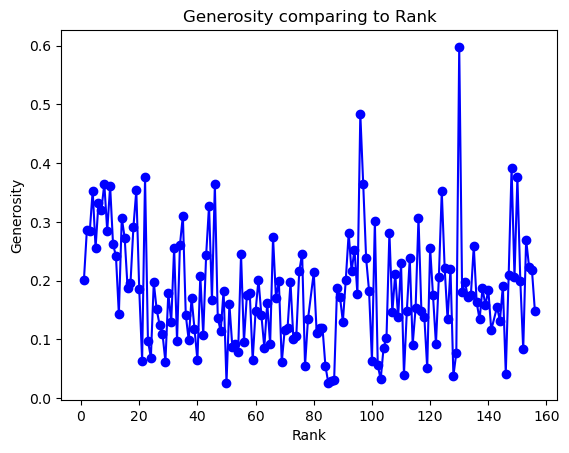

In [11]:
plt.plot(rank, generosity, marker='o', linestyle='-', color='blue')
plt.xlabel('Rank')
plt.ylabel('Generosity')
plt.title('Generosity comparing to Rank')
plt.show()

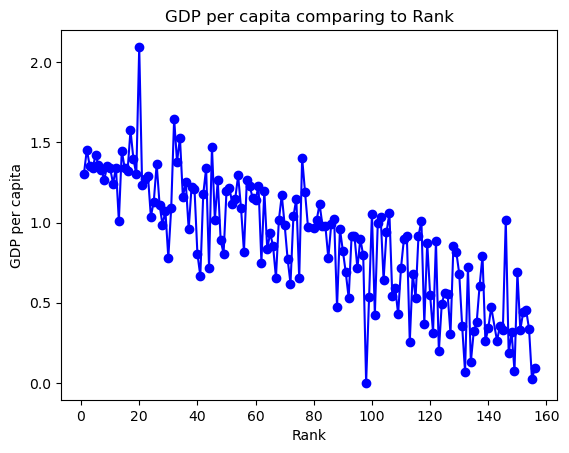

In [12]:
plt.plot(rank, GDP, marker='o', linestyle='-', color='blue')
plt.xlabel('Rank')
plt.ylabel('GDP per capita')
plt.title('GDP per capita comparing to Rank')
plt.show()

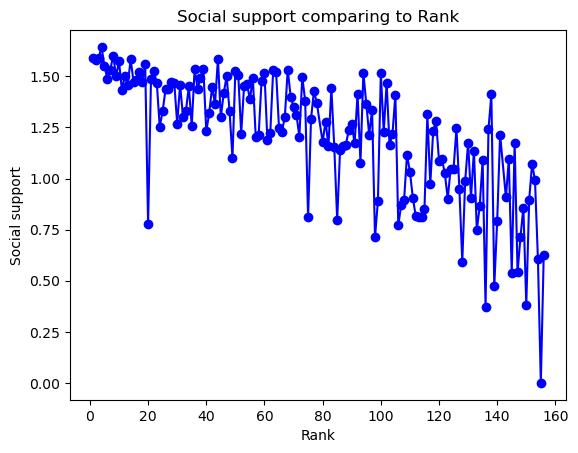

In [13]:
plt.plot(rank, socialSupport, marker='o', linestyle='-', color='blue')
plt.xlabel('Rank')
plt.ylabel('Social support')
plt.title('Social support comparing to Rank')
plt.show()

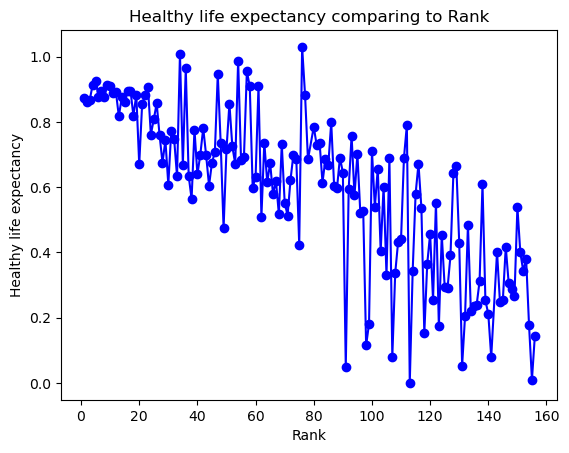

In [14]:
plt.plot(rank, lifex, marker='o', linestyle='-', color='blue')
plt.xlabel('Rank')
plt.ylabel('Healthy life expectancy')
plt.title('Healthy life expectancy comparing to Rank')
plt.show()

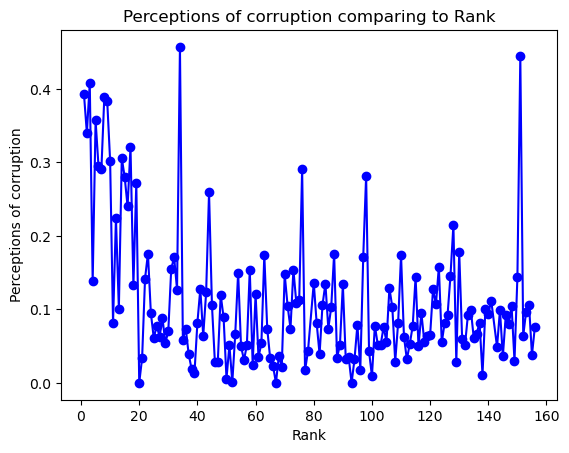

In [15]:
plt.plot(rank, corruption, marker='o', linestyle='-', color='blue')
plt.xlabel('Rank')
plt.ylabel('Perceptions of corruption')
plt.title('Perceptions of corruption comparing to Rank')
plt.show()

sort by regions of interest according to research question

In [16]:
muslim_countries = ['Afghanistan', 'Albania', 'Algeria', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Brunei',
                    'Burkina Faso', 'Chad', 'Comoros',
                    'Djibouti', 'Egypt', 'Gambia', 'Guinea', 'Guinea-Bissau', 'Indonesia', 'Iran', 'Iraq', 'Jordan',
                    'Kazakhstan',
                    'Kuwait', 'Kyrgyzstan', 'Lebanon', 'Libya', 'Malaysia', 'Maldives', 'Mali', 'Mauritania', 'Morocco',
                    'Niger',
                    'Nigeria', 'Oman', 'Pakistan', 'Palestine', 'Qatar', 'Saudi Arabia', 'Senegal', 'Sierra Leone',
                    'Somalia', 'Sudan',
                    'Syria', 'Tajikistan', 'Tunisia', 'Turkey', 'Turkmenistan', 'United Arab Emirates', 'Uzbekistan',
                    'Yemen']

In [17]:
array = []
muslimCountries = np.array(muslim_countries)
for i in range(len(countries)):
    if np.sum(muslimCountries == countries[i]) == 1:
        array.append(freedom[i])
muslimFreedom = np.array(array)

In [18]:
european_countries = ['Albania', 'Andorra', 'Armenia', 'Austria', 'Azerbaijan', 'Belarus', 'Belgium',
                      'Bosnia and Herzegovina', 'Bulgaria',
                      'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Estonia', 'Finland', 'France', 'Georgia',
                      'Germany', 'Greece',
                      'Hungary', 'Iceland', 'Ireland', 'Italy', 'Kazakhstan', 'Kosovo', 'Latvia', 'Liechtenstein',
                      'Lithuania',
                      'Luxembourg', 'Malta', 'Moldova', 'Monaco', 'Montenegro', 'Netherlands', 'North Macedonia',
                      'Norway', 'Poland',
                      'Portugal', 'Romania', 'Russia', 'San Marino', 'Serbia', 'Slovakia', 'Slovenia', 'Spain',
                      'Sweden', 'Switzerland',
                      'Turkey', 'Ukraine', 'United Kingdom', 'Vatican City']

In [19]:
array = []
europeanCountries = np.array(european_countries)
for i in range(len(countries)):
    if np.sum(europeanCountries == countries[i]) == 1:
        array.append(generosity[i])

In [20]:
europeanGenerosity = np.array(array)

In [21]:
asian_countries = ['Afghanistan', 'Armenia', 'Azerbaijan', 'Bahrain', 'Bangladesh', 'Bhutan', 'Brunei', 'Cambodia',
                   'China', 'Cyprus',
                   'Georgia', 'India', 'Indonesia', 'Iran', 'Iraq', 'Israel', 'Japan', 'Jordan', 'Kazakhstan', 'Kuwait',
                   'Kyrgyzstan',
                   'Laos', 'Lebanon', 'Malaysia', 'Maldives', 'Mongolia', 'Myanmar', 'Nepal', 'North Korea', 'Oman',
                   'Pakistan',
                   'Palestine', 'Philippines', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Korea',
                   'Sri Lanka', 'Syria',
                   'Taiwan', 'Tajikistan', 'Thailand', 'Turkey', 'Turkmenistan', 'United Arab Emirates', 'Uzbekistan',
                   'Vietnam',
                   'Yemen']

In [22]:
array = []
asianCountries = np.array(asian_countries)
for i in range(len(countries)):
    if np.sum(asianCountries == countries[i]) == 1:
        array.append(generosity[i])
asianGenerosity = np.array(array)

In [23]:
cut = (freedom.size) // 4
happyCountries = freedom[:cut]   # First quarter

In [24]:
sadCountries = freedom[cut * 3:]    # Last quarter

Now for the DATA ANALYSIS<br>
QUESTION 1

In [25]:
print("\x1B[4m" + "Question 1:" + "\x1B[0m")

Question 1:


Israel's freedom is F<br>
Muslims countries freedom mean is M

H0- F==M<br>
H1- F>M<br>
We hypothesize that Israel has more freedom than Muslim countries

In [26]:
muslimMean = np.mean(muslimFreedom)
muslimStd = np.std(muslimFreedom)
alpha = 0.05
n = np.size(muslimFreedom)
mask = countries == "Israel"
israelFreedom = freedom[mask][0]

In [27]:
se = muslimStd / n ** 0.5
# Sample is bigger than 30 so we can use a z_value
z_value = (israelFreedom - muslimMean) / se
p_value = 1 - sp.norm.cdf(z_value)

In [28]:
if p_value < alpha:
    print("We reject H0, there is more freedom in Israel")
else:
    print("We fail to reject H0, there is not more freedom in Israel")

We reject H0, we approve our hypothesis there is more freedom in Israel


QUESTION 2

In [29]:
print("\x1B[4m" + "Question 2:" + "\x1B[0m")

Question 2:


GA is generosity mean of asian country<br>
GE is generosity mean of european country

H0- GA == GE<br>
H1- GA != GE<br>
We hypothesize that Asia's and Europe's generosity means are significantly different

We acknowledge the fact that variances are unknown and not equal

In [30]:
alpha = 0.1
t_statistic, p_value = sp.ttest_ind(asianGenerosity, europeanGenerosity, equal_var=False)
df = np.size(europeanGenerosity) + np.size(asianGenerosity) - 2
critical_value = sp.t.ppf(1 - alpha / 2, df)

In [31]:
if abs(t_statistic) > critical_value:
    print("We reject H0. There is a significant difference in the means of the generosity between the asian and the european sample.")
else:
    print("We fail to reject H0. There is no significant difference in the means of the generosity between the asian and the european sample.")

We reject H0. There is a significant difference in the means of generosity between the Asian and the European samples. (Asia is significantly more generous)


QUESTION 3

In [32]:
print("\x1B[4m" + "Question 3:" + "\x1B[0m")

Question 3:


FH is the freedom mean of happy countries<br>
FS is the freedom mean of sad countries<br>
We hypothesize that the freedom mean in sad and happy countries is significantly different

H0- FH == FS<br>
H1- FH != FS

We acknowledge the fact that variances are unknown and not equal

In [33]:
alpha = 0.05
t_statistic, p_value = sp.ttest_ind(happyCountries, sadCountries, equal_var=False)
df = np.size(happyCountries) + np.size(sadCountries) - 2
critical_value = sp.t.ppf(1 - alpha / 2, df)

In [34]:
if abs(t_statistic) > critical_value:
    print("We reject H0. There is a significant difference in the means of the freedom between the sad and the happy countries.")
else:
    print("We fail to reject H0. There is no significant difference in the means of the freedom between the sad and the happy countries.")

We reject H0. There is a significant difference between the means of freedom between the sad and the happy countries (freedom is significantly higher in happy countries) 
